1.Import libraries

In [26]:
# import all the required libraries
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import f_classif
from statsmodels.stats.outliers_influence import variance_inflation_factor

.Load The Dataset

In [27]:
# load the data set
df=pd.read_csv("/content/1781453184505-student_dataset_10000_rows.csv")
df.head()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.00,Placed
1,4,69,5,3,8,56,100.00,Placed
2,11,60,7,6,10,45,100.00,Placed
3,8,99,9,8,4,55,90.17,Placed
4,5,52,8,6,8,40,78.82,Placed


Inspect the data

In [28]:
# shape of data set
df.shape

(10000, 8)

In [29]:
# info of the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   study_hours            10000 non-null  int64  
 1   attendance             10000 non-null  int64  
 2   sleep_hours            10000 non-null  int64  
 3   internet_usage         10000 non-null  int64  
 4   assignments_completed  10000 non-null  int64  
 5   previous_score         10000 non-null  int64  
 6   exam_score             10000 non-null  float64
 7   placement_status       10000 non-null  object 
dtypes: float64(1), int64(6), object(1)
memory usage: 625.1+ KB


In [30]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
study_hours,10000.0,5.989600,3.163589,1.00,3.0000,6.00,9.0,11.0
attendance,10000.0,69.884600,17.616530,40.00,55.0000,70.00,85.0,100.0
sleep_hours,10000.0,6.498500,1.709354,4.00,5.0000,6.50,8.0,9.0
internet_usage,10000.0,6.062600,3.138163,1.00,3.0000,6.00,9.0,11.0
assignments_completed,10000.0,9.988400,6.034145,0.00,5.0000,10.00,15.0,20.0
previous_score,10000.0,64.911000,17.503020,35.00,50.0000,65.00,80.0,95.0
exam_score,10000.0,86.704207,15.058383,26.67,76.7275,92.12,100.0,100.0


**How balanced is the target**

In [31]:
print(df["placement_status"].value_counts())
print()
print((df["placement_status"].value_counts(normalize=True) * 100).round(1))

placement_status
Placed        8356
Not Placed    1644
Name: count, dtype: int64

placement_status
Placed        83.6
Not Placed    16.4
Name: proportion, dtype: float64


**2. Data cleaning**

Missing values

In [32]:
missing = df.isnull().sum()
print(missing)
print()
print("Total missing values:", int(missing.sum()))

study_hours              0
attendance               0
sleep_hours              0
internet_usage           0
assignments_completed    0
previous_score           0
exam_score               0
placement_status         0
dtype: int64

Total missing values: 0


In [33]:
# If any value were missing: numbers -> fill with median, text -> fill with most common value.
# (This data has none, but the code makes the notebook safe for other data.)

for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])
print("Missing values left:", int(df.isnull().sum().sum()))

Missing values left: 0


**`Duplicate rows`**

In [34]:
print("Duplicate rows found:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(df))

Duplicate rows found: 0
Rows after removing duplicates: 10000


**Impossible values (range check)**

In [35]:
checks = {
    "attendance is between 0 and 100": df["attendance"].between(0, 100).all(),
    "previous_score is between 0 and 100": df["previous_score"].between(0, 100).all(),
    "exam_score is between 0 and 100": df["exam_score"].between(0, 100).all(),
    "sleep_hours is between 0 and 24": df["sleep_hours"].between(0, 24).all(),
    "assignments_completed is 0 or more": (df["assignments_completed"] >= 0).all(),
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)

PASS - attendance is between 0 and 100
PASS - previous_score is between 0 and 100
PASS - exam_score is between 0 and 100
PASS - sleep_hours is between 0 and 24
PASS - assignments_completed is 0 or more


In [36]:
# One more check: study + sleep + internet hours should not be more than 24 in one day.
total = df["study_hours"] + df["sleep_hours"] + df["internet_usage"]
too_many = int((total > 24).sum())
print("Students with study + sleep + internet above 24 hours:", too_many, "(%.1f%%)" % (too_many / len(df) * 100))

# We do not delete these rows (that would lose 11% of the data). We mark them with a flag instead.
df["Hours_Over_24_Flag"] = (total > 24).astype(int)

Students with study + sleep + internet above 24 hours: 1127 (11.3%)


**Outliers**

In [37]:
num_cols = ["study_hours", "attendance", "sleep_hours", "internet_usage",
            "assignments_completed", "previous_score", "exam_score"]

rows = []
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = int(((df[col] < low) | (df[col] > high)).sum())
    rows.append([col, round(low, 1), round(high, 1), count])

pd.DataFrame(rows, columns=["column", "lower_limit", "upper_limit", "outliers"])

,column,lower_limit,upper_limit,outliers
0,study_hours,-6.0,18.0,0
1,attendance,10.0,130.0,0
2,sleep_hours,0.5,12.5,0
3,internet_usage,-6.0,18.0,0
4,assignments_completed,-10.0,30.0,0
5,previous_score,5.0,125.0,0
6,exam_score,41.8,134.9,62


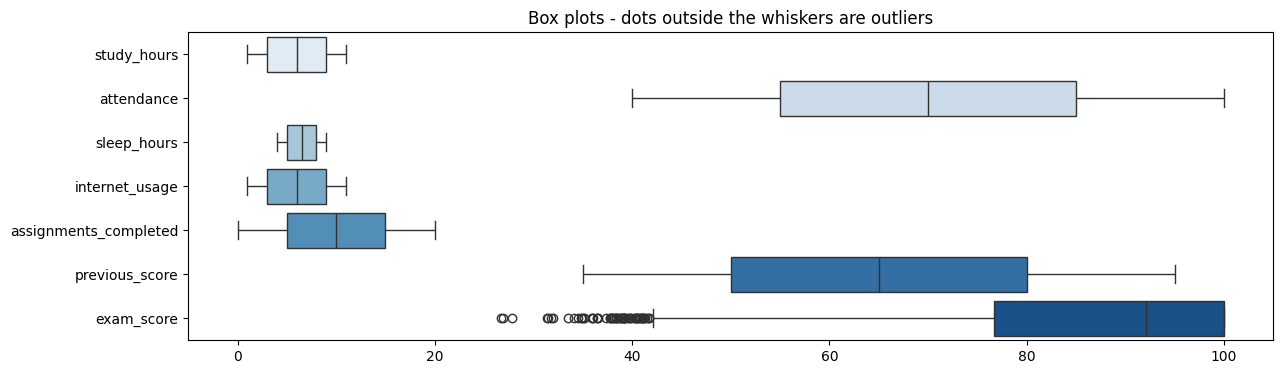

In [38]:
plt.figure(figsize=(14, 4))
sns.boxplot(data=df[num_cols], orient="h", palette="Blues")
plt.title("Box plots - dots outside the whiskers are outliers")
plt.show()

In [39]:
q1 = df["exam_score"].quantile(0.25)
q3 = df["exam_score"].quantile(0.75)
lower_limit = q1 - 1.5 * (q3 - q1)
df["Low_Score_Flag"] = (df["exam_score"] < lower_limit).astype(int)
print("Students flagged with a very low exam score:", int(df["Low_Score_Flag"].sum()))

df_clean = df.copy()
print("Cleaned data shape:", df_clean.shape)

Students flagged with a very low exam score: 62
Cleaned data shape: (10000, 10)


3.Data Transformation

In [40]:
df_clean["placement_status"] = df_clean["placement_status"].str.strip().str.title()

# Label encoding of the target
df_clean["Placed"] = df_clean["placement_status"].map({"Placed": 1, "Not Placed": 0})

# Correct data types
whole_cols = ["study_hours", "attendance", "sleep_hours", "internet_usage",
              "assignments_completed", "previous_score"]
df_clean[whole_cols] = df_clean[whole_cols].astype(int)
df_clean["exam_score"] = df_clean["exam_score"].round(2)

print(df_clean[["placement_status", "Placed"]].drop_duplicates())
print()
print(df_clean.dtypes)

   placement_status  Placed
0            Placed       1
16       Not Placed       0

study_hours                int64
attendance                 int64
sleep_hours                int64
internet_usage             int64
assignments_completed      int64
previous_score             int64
exam_score               float64
placement_status          object
Hours_Over_24_Flag         int64
Low_Score_Flag             int64
Placed                     int64
dtype: object


In [41]:
skew = df_clean[num_cols].skew().round(2)
print(skew)
print()
print("Rule of thumb: skew between -0.5 and 0.5 = fairly even. Our input columns are all close to 0, so they need no transformation.")

study_hours             -0.01
attendance               0.02
sleep_hours              0.01
internet_usage          -0.01
assignments_completed    0.02
previous_score           0.00
exam_score              -1.01
dtype: float64

Rule of thumb: skew between -0.5 and 0.5 = fairly even. Our input columns are all close to 0, so they need no transformation.


4.Feature Engineering

In [42]:
df_fe = df_clean.copy()

df_fe["Total_Daily_Hours"] = df_fe["study_hours"] + df_fe["sleep_hours"] + df_fe["internet_usage"]
df_fe["Study_Internet_Ratio"] = (df_fe["study_hours"] / df_fe["internet_usage"]).round(3)
df_fe["Assignment_Completion_Pct"] = (df_fe["assignments_completed"] / 20 * 100).round(1)

print("Skew of the new ratio column:", round(df_fe["Study_Internet_Ratio"].skew(), 2))

Skew of the new ratio column: 2.74


Skew after log transform: 1.16


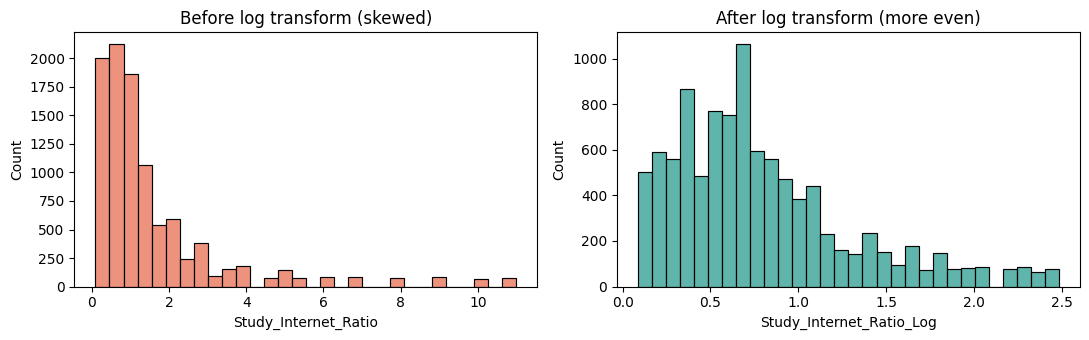

In [43]:
df_fe["Study_Internet_Ratio_Log"] = np.log1p(df_fe["Study_Internet_Ratio"]).round(4)
print("Skew after log transform:", round(df_fe["Study_Internet_Ratio_Log"].skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df_fe["Study_Internet_Ratio"], bins=30, ax=axes[0], color="#e76f51")
axes[0].set_title("Before log transform (skewed)")
sns.histplot(df_fe["Study_Internet_Ratio_Log"], bins=30, ax=axes[1], color="#2a9d8f")
axes[1].set_title("After log transform (more even)")
plt.tight_layout()
plt.show()

In [44]:
# Grouping numbers into readable bands (useful for charts and dashboards)
def make_band(series, edges, names):
    return pd.cut(series, bins=edges, labels=names, include_lowest=True).astype(str)

df_fe["Study_Level"] = make_band(df_fe["study_hours"], [0, 3, 7, 24], ["Low", "Medium", "High"])
df_fe["Attendance_Level"] = make_band(df_fe["attendance"], [0, 59, 74, 89, 100], ["Poor", "Average", "Good", "Excellent"])
df_fe["Exam_Grade"] = make_band(df_fe["exam_score"], [0, 59.99, 69.99, 79.99, 89.99, 100], ["F", "D", "C", "B", "A"])

df_fe.insert(0, "Student_ID", np.arange(1, len(df_fe) + 1))
print("Shape after feature engineering:", df_fe.shape)
df_fe.head()

Shape after feature engineering: (10000, 19)


,Student_ID,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status,Hours_Over_24_Flag,Low_Score_Flag,Placed,Total_Daily_Hours,Study_Internet_Ratio,Assignment_Completion_Pct,Study_Internet_Ratio_Log,Study_Level,Attendance_Level,Exam_Grade
0,1,7,56,8,7,10,62,100.00,Placed,0,0,1,22,1.000,50.0,0.6931,Medium,Poor,A
1,2,4,69,5,3,8,56,100.00,Placed,0,0,1,12,1.333,40.0,0.8472,Medium,Average,A
2,3,11,60,7,6,10,45,100.00,Placed,0,0,1,24,1.833,50.0,1.0413,High,Average,A
3,4,8,99,9,8,4,55,90.17,Placed,1,0,1,25,1.000,20.0,0.6931,High,Excellent,A
4,5,5,52,8,6,8,40,78.82,Placed,0,0,1,19,0.833,40.0,0.6060,Medium,Poor,C


5.Feature selection

In [48]:
# leakage test
print(df_fe.groupby("placement_status")["exam_score"].agg(["min", "max"]))
rule = (df_fe["exam_score"] >= 70).astype(int)
print()
print("If we simply say 'exam_score 70 or more = Placed', we are right %.1f%% of the time." % ((rule == df_fe["Placed"]).mean() * 100))

                    min     max
placement_status               
Not Placed        26.67   69.99
Placed            70.02  100.00

If we simply say 'exam_score 70 or more = Placed', we are right 100.0% of the time.


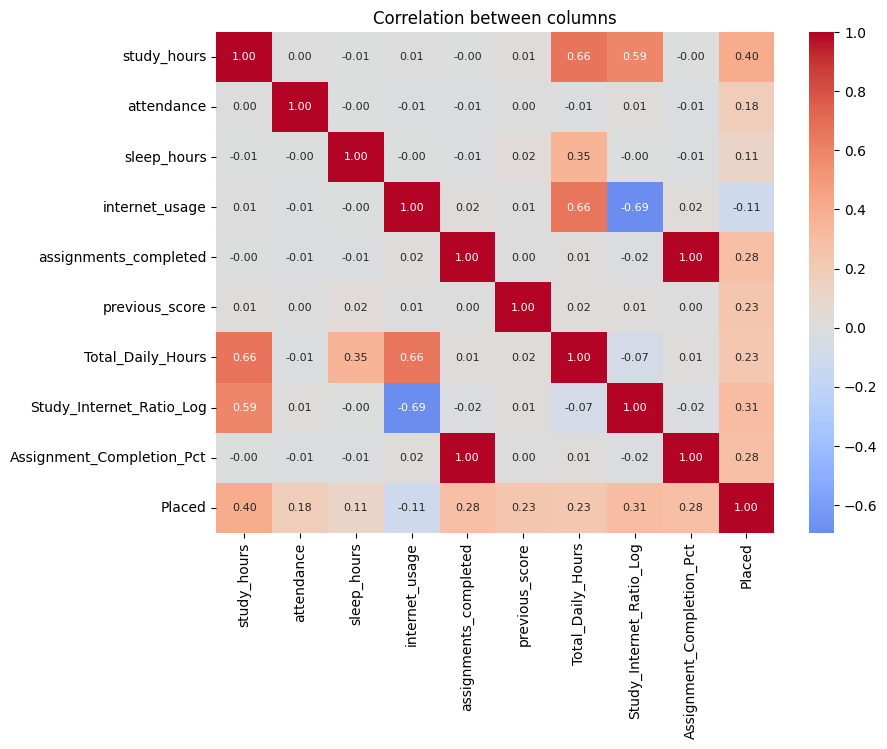

Pairs that are nearly identical (correlation above 0.9):
   assignments_completed and Assignment_Completion_Pct -> 1.0


In [45]:
# correlation test
candidates = ["study_hours", "attendance", "sleep_hours", "internet_usage",
              "assignments_completed", "previous_score",
              "Total_Daily_Hours", "Study_Internet_Ratio_Log", "Assignment_Completion_Pct"]

plt.figure(figsize=(9, 6.5))
sns.heatmap(df_fe[candidates + ["Placed"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Correlation between columns")
plt.show()

corr = df_fe[candidates].corr().abs()
print("Pairs that are nearly identical (correlation above 0.9):")
for i in range(len(candidates)):
    for j in range(i + 1, len(candidates)):
        if corr.iloc[i, j] > 0.9:
            print("  ", candidates[i], "and", candidates[j], "->", round(corr.iloc[i, j], 3))

In [49]:
candidates = [c for c in candidates if c != "Assignment_Completion_Pct"]
print("Columns left:", candidates)

Columns left: ['study_hours', 'attendance', 'sleep_hours', 'internet_usage', 'assignments_completed', 'previous_score', 'Total_Daily_Hours', 'Study_Internet_Ratio_Log']


                     feature  F_score  p_value
0                study_hours   1915.0      0.0
1   Study_Internet_Ratio_Log   1052.3      0.0
2      assignments_completed    851.4      0.0
3  Assignment_Completion_Pct    851.4      0.0
4             previous_score    572.3      0.0
5          Total_Daily_Hours    571.3      0.0
6                 attendance    322.4      0.0
7                sleep_hours    123.8      0.0
8             internet_usage    123.0      0.0


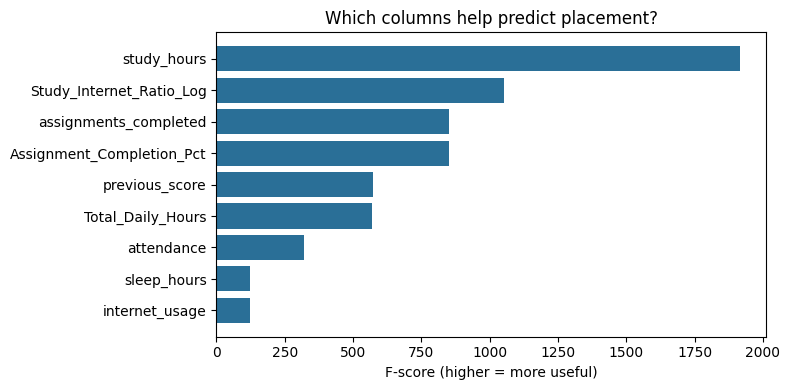

In [46]:
# f-test
f_scores, p_values = f_classif(df_fe[candidates], df_fe["Placed"])
f_table = pd.DataFrame({"feature": candidates, "F_score": f_scores.round(1), "p_value": p_values.round(4)})
f_table = f_table.sort_values("F_score", ascending=False).reset_index(drop=True)
print(f_table)

plt.figure(figsize=(8, 4))
plt.barh(f_table["feature"][::-1], f_table["F_score"][::-1], color="#2a6f97")
plt.xlabel("F-score (higher = more useful)")
plt.title("Which columns help predict placement?")
plt.tight_layout()
plt.show()

In [50]:
# repeated information test
def vif_table(columns):
    X = df_fe[columns].astype(float).copy()
    X.insert(0, "const", 1.0)
    values = [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])]
    return pd.DataFrame({"feature": columns, "VIF": np.round(values, 2)}).sort_values("VIF", ascending=False)

print("VIF with all columns:")
print(vif_table(candidates))

VIF with all columns:
                    feature           VIF
0               study_hours  1.000800e+15
2               sleep_hours  1.000800e+15
3            internet_usage  1.000800e+15
6         Total_Daily_Hours  1.000800e+15
7  Study_Internet_Ratio_Log  6.020000e+00
1                attendance  1.000000e+00
5            previous_score  1.000000e+00
4     assignments_completed  1.000000e+00


In [51]:
# Remove the column that was built from the others
selected = [c for c in candidates if c != "Total_Daily_Hours"]

print("VIF after removing Total_Daily_Hours:")
print(vif_table(selected))
print()
print("All VIF values below 10?", bool((vif_table(selected)["VIF"] < 10).all()))

VIF after removing Total_Daily_Hours:
                    feature   VIF
6  Study_Internet_Ratio_Log  6.02
3            internet_usage  3.93
0               study_hours  3.12
2               sleep_hours  1.00
1                attendance  1.00
4     assignments_completed  1.00
5            previous_score  1.00

All VIF values below 10? True


In [52]:
print("FINAL SELECTED FEATURES (%d):" % len(selected))
for name in selected:
    print("  -", name)

dropped = [c for c in df_fe.columns if c not in selected + ["Placed"]]
print()
print("Columns not used for the model:", dropped)

FINAL SELECTED FEATURES (7):
  - study_hours
  - attendance
  - sleep_hours
  - internet_usage
  - assignments_completed
  - previous_score
  - Study_Internet_Ratio_Log

Columns not used for the model: ['Student_ID', 'exam_score', 'placement_status', 'Hours_Over_24_Flag', 'Low_Score_Flag', 'Total_Daily_Hours', 'Study_Internet_Ratio', 'Assignment_Completion_Pct', 'Study_Level', 'Attendance_Level', 'Exam_Grade']


**6.Data splitting**


In [53]:
X = df_fe[selected]
y = df_fe["Placed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print("Training set:", X_train.shape, "| Placed: %.1f%%" % (y_train.mean() * 100))
print("Test set    :", X_test.shape, "| Placed: %.1f%%" % (y_test.mean() * 100))

Training set: (8000, 7) | Placed: 83.6%
Test set    : (2000, 7) | Placed: 83.5%


**7.scaling**

In [54]:
std_scaler = StandardScaler()
std_scaler.fit(X_train)

X_train_std = pd.DataFrame(std_scaler.transform(X_train), columns=selected, index=X_train.index).round(4)
X_test_std = pd.DataFrame(std_scaler.transform(X_test), columns=selected, index=X_test.index).round(4)

print("Training set after standardization (average should be about 0, spread about 1):")
print(X_train_std.describe().loc[["mean", "std"]].round(2))

Training set after standardization (average should be about 0, spread about 1):
      study_hours  attendance  sleep_hours  internet_usage  \
mean          0.0        -0.0         -0.0            -0.0   
std           1.0         1.0          1.0             1.0   

      assignments_completed  previous_score  Study_Internet_Ratio_Log  
mean                   -0.0            -0.0                       0.0  
std                     1.0             1.0                       1.0  


**8.Normalization**

In [55]:
norm_scaler = MinMaxScaler()
norm_scaler.fit(X_train)

X_train_norm = pd.DataFrame(norm_scaler.transform(X_train), columns=selected, index=X_train.index).round(4)
X_test_norm = pd.DataFrame(norm_scaler.transform(X_test), columns=selected, index=X_test.index).round(4)

print("Training set after normalization (minimum should be 0, maximum 1):")
print(X_train_norm.describe().loc[["min", "max"]].round(2))

Training set after normalization (minimum should be 0, maximum 1):
     study_hours  attendance  sleep_hours  internet_usage  \
min          0.0         0.0          0.0             0.0   
max          1.0         1.0          1.0             1.0   

     assignments_completed  previous_score  Study_Internet_Ratio_Log  
min                    0.0             0.0                       0.0  
max                    1.0             1.0                       1.0  


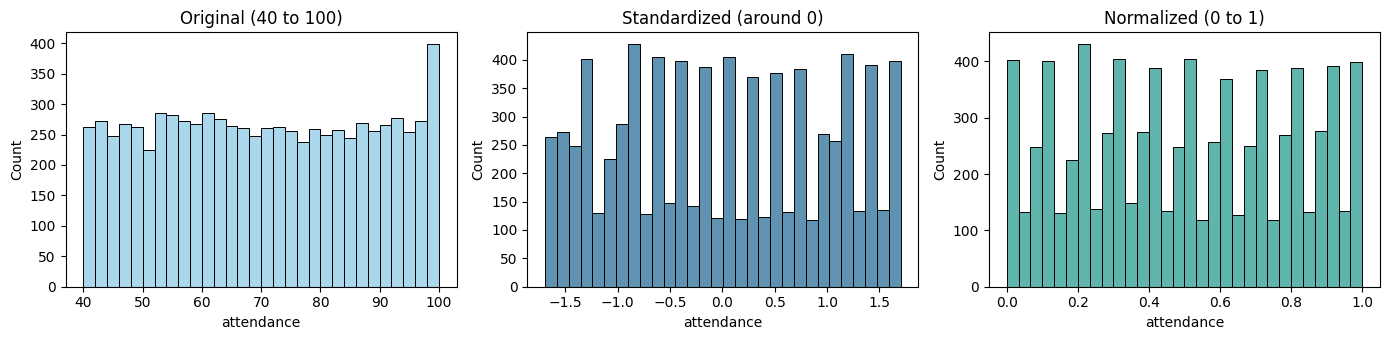

In [56]:
# See the difference: original vs standardized vs normalized (example column: attendance)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
sns.histplot(X_train["attendance"], bins=30, ax=axes[0], color="#8ecae6")
axes[0].set_title("Original (40 to 100)")
sns.histplot(X_train_std["attendance"], bins=30, ax=axes[1], color="#2a6f97")
axes[1].set_title("Standardized (around 0)")
sns.histplot(X_train_norm["attendance"], bins=30, ax=axes[2], color="#2a9d8f")
axes[2].set_title("Normalized (0 to 1)")
plt.tight_layout()
plt.show()

**save all the files **

In [57]:
# optional
OUT = "preprocessing_outputs"
os.makedirs(OUT, exist_ok=True)

# 1. Cleaned data (after Steps 2-3)
df_clean.to_csv(OUT + "/1_cleaned_data.csv", index=False)

# 2. All columns after feature engineering (use this one for Power BI)
df_fe.to_csv(OUT + "/2_feature_engineered_data.csv", index=False)

# 3. Only the selected features + target
df_fe[["Student_ID"] + selected + ["Placed"]].to_csv(OUT + "/3_selected_features_data.csv", index=False)

# 4. Train / test sets (original values)
train_raw = X_train.copy(); train_raw["Placed"] = y_train
test_raw = X_test.copy(); test_raw["Placed"] = y_test
train_raw.to_csv(OUT + "/4_train_original.csv", index=False)
test_raw.to_csv(OUT + "/4_test_original.csv", index=False)

# 5. Standardized train / test
train_std = X_train_std.copy(); train_std["Placed"] = y_train
test_std = X_test_std.copy(); test_std["Placed"] = y_test
train_std.to_csv(OUT + "/5_train_standardized.csv", index=False)
test_std.to_csv(OUT + "/5_test_standardized.csv", index=False)

# 6. Normalized train / test
train_norm = X_train_norm.copy(); train_norm["Placed"] = y_train
test_norm = X_test_norm.copy(); test_norm["Placed"] = y_test
train_norm.to_csv(OUT + "/6_train_normalized.csv", index=False)
test_norm.to_csv(OUT + "/6_test_normalized.csv", index=False)

for name in sorted(os.listdir(OUT)):
    size = pd.read_csv(OUT + "/" + name).shape
    print(name.ljust(36), "rows:", size[0], " columns:", size[1])

1_cleaned_data.csv                   rows: 10000  columns: 11
2_feature_engineered_data.csv        rows: 10000  columns: 19
3_selected_features_data.csv         rows: 10000  columns: 9
4_test_original.csv                  rows: 2000  columns: 8
4_train_original.csv                 rows: 8000  columns: 8
5_test_standardized.csv              rows: 2000  columns: 8
5_train_standardized.csv             rows: 8000  columns: 8
6_test_normalized.csv                rows: 2000  columns: 8
6_train_normalized.csv               rows: 8000  columns: 8
